<a href="https://colab.research.google.com/github/Noorain-Malik/netflix-customer-churn-prediction/blob/main/model-traning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
file_path = "/content/drive/MyDrive/Netflix_Churn_Project/netflix_customer_churn.csv"

df = pd.read_csv(file_path)

Mounted at /content/drive


In [2]:
print(df.shape)
print(df.info())

(5000, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   customer_id             5000 non-null   object 
 1   age                     5000 non-null   int64  
 2   gender                  5000 non-null   object 
 3   subscription_type       5000 non-null   object 
 4   watch_hours             5000 non-null   float64
 5   last_login_days         5000 non-null   int64  
 6   region                  5000 non-null   object 
 7   device                  5000 non-null   object 
 8   monthly_fee             5000 non-null   float64
 9   churned                 5000 non-null   int64  
 10  payment_method          5000 non-null   object 
 11  number_of_profiles      5000 non-null   int64  
 12  avg_watch_time_per_day  5000 non-null   float64
 13  favorite_genre          5000 non-null   object 
dtypes: float64(3), int64(4), obje

In [3]:
print(df.head())
print(df.columns)

                            customer_id  age  gender subscription_type  \
0  a9b75100-82a8-427a-a208-72f24052884a   51   Other             Basic   
1  49a5dfd9-7e69-4022-a6ad-0a1b9767fb5b   47   Other          Standard   
2  4d71f6ce-fca9-4ff7-8afa-197ac24de14b   27  Female          Standard   
3  d3c72c38-631b-4f9e-8a0e-de103cad1a7d   53   Other           Premium   
4  4e265c34-103a-4dbb-9553-76c9aa47e946   56   Other          Standard   

   watch_hours  last_login_days   region  device  monthly_fee  churned  \
0        14.73               29   Africa      TV         8.99        1   
1         0.70               19   Europe  Mobile        13.99        1   
2        16.32               10     Asia      TV        13.99        0   
3         4.51               12  Oceania      TV        17.99        1   
4         1.89               13   Africa  Mobile        13.99        1   

  payment_method  number_of_profiles  avg_watch_time_per_day favorite_genre  
0      Gift Card                

In [4]:
print(df.describe())

print(df.describe(include="object"))


print(df.nunique())


               age  watch_hours  last_login_days  monthly_fee      churned  \
count  5000.000000  5000.000000      5000.000000  5000.000000  5000.000000   
mean     43.847400    11.649450        30.089800    13.683400     0.503000   
std      15.501128    12.014654        17.536078     3.692062     0.500041   
min      18.000000     0.010000         0.000000     8.990000     0.000000   
25%      30.000000     3.337500        15.000000     8.990000     0.000000   
50%      44.000000     8.000000        30.000000    13.990000     1.000000   
75%      58.000000    16.030000        45.000000    17.990000     1.000000   
max      70.000000   110.400000        60.000000    17.990000     1.000000   

       number_of_profiles  avg_watch_time_per_day  
count         5000.000000             5000.000000  
mean             3.024400                0.874800  
std              1.415841                2.619824  
min              1.000000                0.000000  
25%              2.000000            

In [5]:
print("Missing Values in Each Column:")
print(df.isnull().sum())

print("\nPercentage of Missing Values:")
print((df.isnull().sum() / len(df)) * 100)

Missing Values in Each Column:
customer_id               0
age                       0
gender                    0
subscription_type         0
watch_hours               0
last_login_days           0
region                    0
device                    0
monthly_fee               0
churned                   0
payment_method            0
number_of_profiles        0
avg_watch_time_per_day    0
favorite_genre            0
dtype: int64

Percentage of Missing Values:
customer_id               0.0
age                       0.0
gender                    0.0
subscription_type         0.0
watch_hours               0.0
last_login_days           0.0
region                    0.0
device                    0.0
monthly_fee               0.0
churned                   0.0
payment_method            0.0
number_of_profiles        0.0
avg_watch_time_per_day    0.0
favorite_genre            0.0
dtype: float64


In [6]:
print("Total Duplicate Rows:")
print(df.duplicated().sum())

categorical_cols = df.select_dtypes(include=["object", "category"]).columns

for col in categorical_cols:
    print(f"\nColumn: {col}")
    print(df[col].value_counts(dropna=False))

Total Duplicate Rows:
0

Column: customer_id
customer_id
a9b75100-82a8-427a-a208-72f24052884a    1
49a5dfd9-7e69-4022-a6ad-0a1b9767fb5b    1
4d71f6ce-fca9-4ff7-8afa-197ac24de14b    1
d3c72c38-631b-4f9e-8a0e-de103cad1a7d    1
4e265c34-103a-4dbb-9553-76c9aa47e946    1
                                       ..
44f3ba44-b95d-4e50-a786-bac4d06f4a43    1
18779bcb-ba2b-41da-b751-e70b812061ec    1
3f32e8c5-615b-4a3b-a864-db2688f7834f    1
7b0ad82d-6571-430e-90f4-906259e0e89c    1
82aeef39-ddb0-40ad-bae1-5c436e0cf042    1
Name: count, Length: 5000, dtype: int64

Column: gender
gender
Female    1711
Male      1654
Other     1635
Name: count, dtype: int64

Column: subscription_type
subscription_type
Premium     1693
Basic       1661
Standard    1646
Name: count, dtype: int64

Column: region
region
South America    873
Europe           867
North America    851
Asia             841
Africa           803
Oceania          765
Name: count, dtype: int64

Column: device
device
Tablet     1048
Laptop     

In [7]:
print("Duplicate Customer IDs:", df["customer_id"].duplicated().sum())

Duplicate Customer IDs: 0


In [8]:
print("Missing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

Missing Values:
customer_id               0
age                       0
gender                    0
subscription_type         0
watch_hours               0
last_login_days           0
region                    0
device                    0
monthly_fee               0
churned                   0
payment_method            0
number_of_profiles        0
avg_watch_time_per_day    0
favorite_genre            0
dtype: int64

Total Missing Values:
0


In [9]:
categorical_cols = df.select_dtypes(include=["object", "category"]).columns

for col in categorical_cols:
    blank_count = df[col].astype("string").str.strip().eq("").sum()
    print(f"{col}: {blank_count} blank values")

customer_id: 0 blank values
gender: 0 blank values
subscription_type: 0 blank values
region: 0 blank values
device: 0 blank values
payment_method: 0 blank values
favorite_genre: 0 blank values


In [10]:
numeric_cols = df.select_dtypes(include="number").columns

print("Minimum Values:")
print(df[numeric_cols].min())

print("\nMaximum Values:")
print(df[numeric_cols].max())

print("\nChurn Target Values:")
print(df["churned"].value_counts())

Minimum Values:
age                       18.00
watch_hours                0.01
last_login_days            0.00
monthly_fee                8.99
churned                    0.00
number_of_profiles         1.00
avg_watch_time_per_day     0.00
dtype: float64

Maximum Values:
age                        70.00
watch_hours               110.40
last_login_days            60.00
monthly_fee                17.99
churned                     1.00
number_of_profiles          5.00
avg_watch_time_per_day     98.42
dtype: float64

Churn Target Values:
churned
1    2515
0    2485
Name: count, dtype: int64


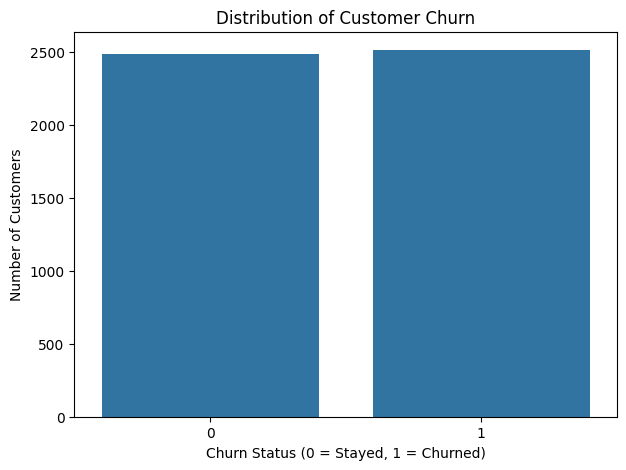

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="churned")

plt.title("Distribution of Customer Churn")
plt.xlabel("Churn Status (0 = Stayed, 1 = Churned)")
plt.ylabel("Number of Customers")

plt.show()

In [12]:
print("Churn Counts:")
print(df["churned"].value_counts())

print("\nChurn Percentages:")
print(df["churned"].value_counts(normalize=True) * 100)

Churn Counts:
churned
1    2515
0    2485
Name: count, dtype: int64

Churn Percentages:
churned
1    50.3
0    49.7
Name: proportion, dtype: float64


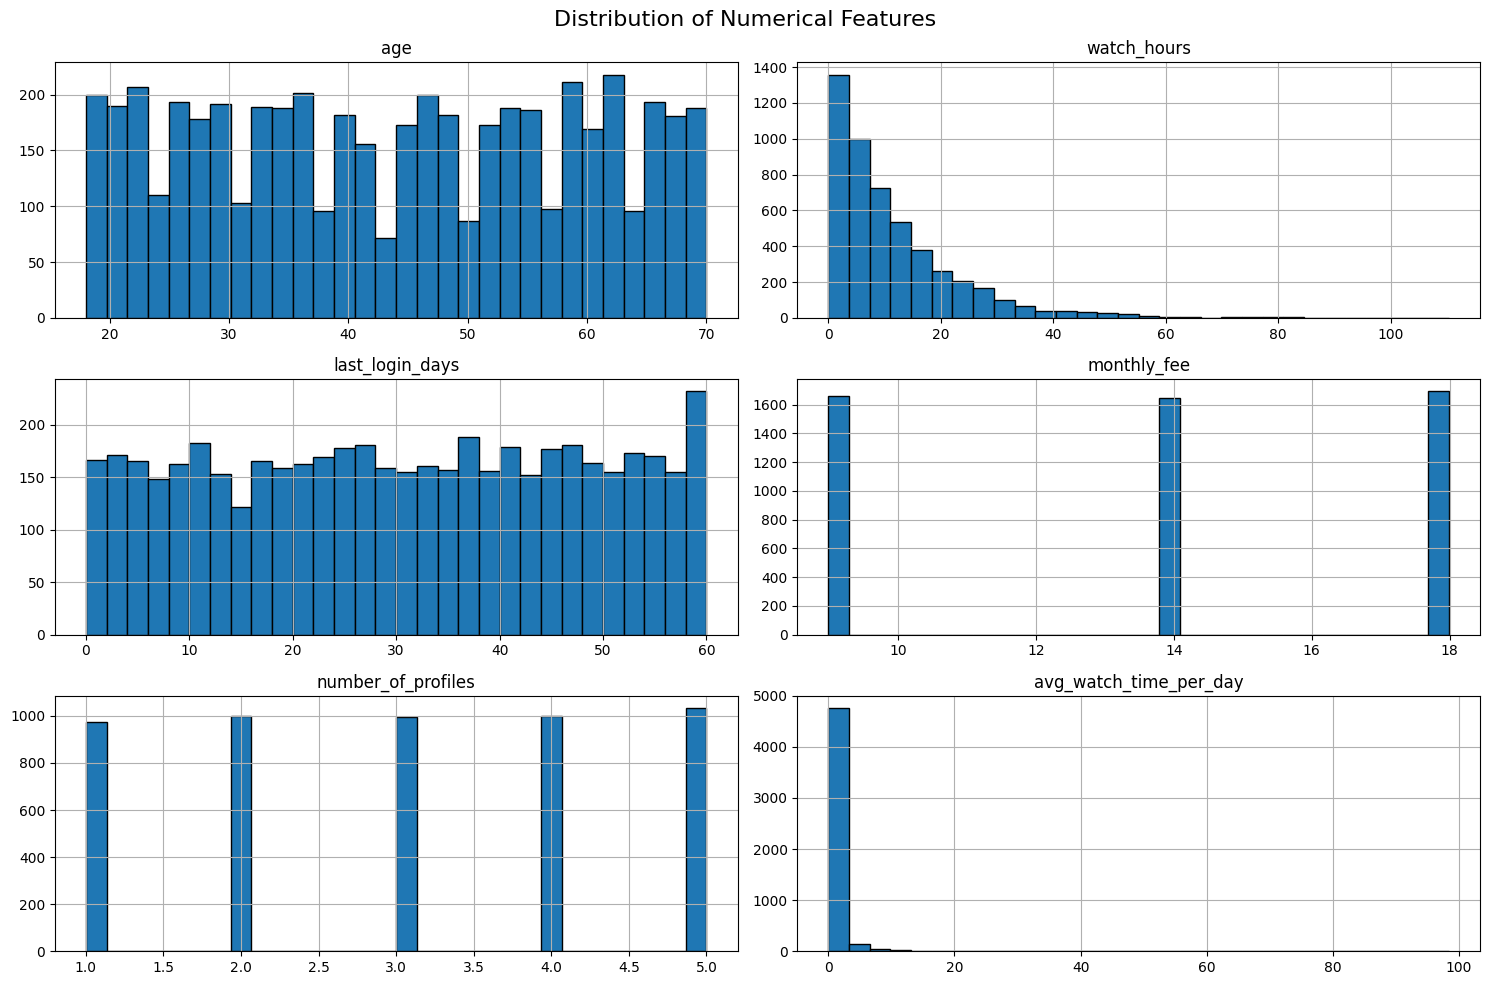

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Select numerical columns
numeric_cols = df.select_dtypes(include=np.number).columns

# Exclude target variable
numeric_cols = numeric_cols.drop("churned", errors="ignore")

# Create histograms
df[numeric_cols].hist(
    figsize=(15, 10),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Features", fontsize=16)
plt.tight_layout()
plt.show()

In [14]:
print("Skewness of Numerical Features:")
print(df[numeric_cols].skew().sort_values(ascending=False))
print("Maximum average watch time per day:")
print(df["avg_watch_time_per_day"].max())

print("\nTop 10 highest values:")
print(df["avg_watch_time_per_day"].nlargest(10))

Skewness of Numerical Features:
avg_watch_time_per_day    15.834680
watch_hours                2.259195
age                        0.006334
number_of_profiles        -0.016895
last_login_days           -0.025977
monthly_fee               -0.144942
dtype: float64
Maximum average watch time per day:
98.42

Top 10 highest values:
2017    98.42
1219    52.80
2564    34.53
4792    32.88
4078    32.81
4805    29.55
3641    28.66
4285    27.27
4845    26.98
647     25.15
Name: avg_watch_time_per_day, dtype: float64


In [15]:
print("Values greater than 24 hours:")
print((df["avg_watch_time_per_day"] > 24).sum())

print("\nPercentage of values greater than 24:")
print((df["avg_watch_time_per_day"] > 24).mean() * 100)

print("\nSummary statistics:")
print(df["avg_watch_time_per_day"].describe())

Values greater than 24 hours:
10

Percentage of values greater than 24:
0.2

Summary statistics:
count    5000.000000
mean        0.874800
std         2.619824
min         0.000000
25%         0.110000
50%         0.290000
75%         0.720000
max        98.420000
Name: avg_watch_time_per_day, dtype: float64


In [16]:
print(
    df.loc[
        df["avg_watch_time_per_day"] > 24,
        [
            "customer_id",
            "watch_hours",
            "avg_watch_time_per_day",
            "churned"
        ]
    ]
)

                               customer_id  watch_hours  \
647   c350d5a0-fef7-4281-b752-42162d72bd05        25.15   
1219  45ea1095-e06b-4a1c-a0b7-c3671c9f006a        52.80   
2017  23e2a122-9e50-41d8-a434-c25675765f79        98.42   
2564  511d9a10-669b-4283-bc6d-40c10a595b43        34.53   
3641  64d85f24-42f8-48b1-8675-590db42d23e5        28.66   
4078  9adb0b11-3199-438c-9b3c-59dee22c6b27        32.81   
4285  3878e4e3-2960-4b36-b25c-f90ddd01b5d8        54.53   
4792  88a98e69-9e49-4d28-98d7-1e0b1bce6138        32.88   
4805  b906246e-44aa-441f-85c5-fc2aa946b0cb        29.55   
4845  d202349e-dd45-42e7-84a9-fa604082763f        26.98   

      avg_watch_time_per_day  churned  
647                    25.15        0  
1219                   52.80        0  
2017                   98.42        0  
2564                   34.53        0  
3641                   28.66        0  
4078                   32.81        0  
4285                   27.27        0  
4792                   32.88  

In [17]:
print("Correlation:")
print(df[["watch_hours", "avg_watch_time_per_day"]].corr())

print("\nRatio of watch hours to average daily watch time:")
print(
    (df["watch_hours"] /
     df["avg_watch_time_per_day"].replace(0, np.nan))
    .describe()
)

Correlation:
                        watch_hours  avg_watch_time_per_day
watch_hours                1.000000                0.349742
avg_watch_time_per_day     0.349742                1.000000

Ratio of watch hours to average daily watch time:
count    4948.000000
mean       30.941734
std        17.693961
min         1.000000
25%        16.000000
50%        30.860390
75%        45.868750
max        87.000000
dtype: float64


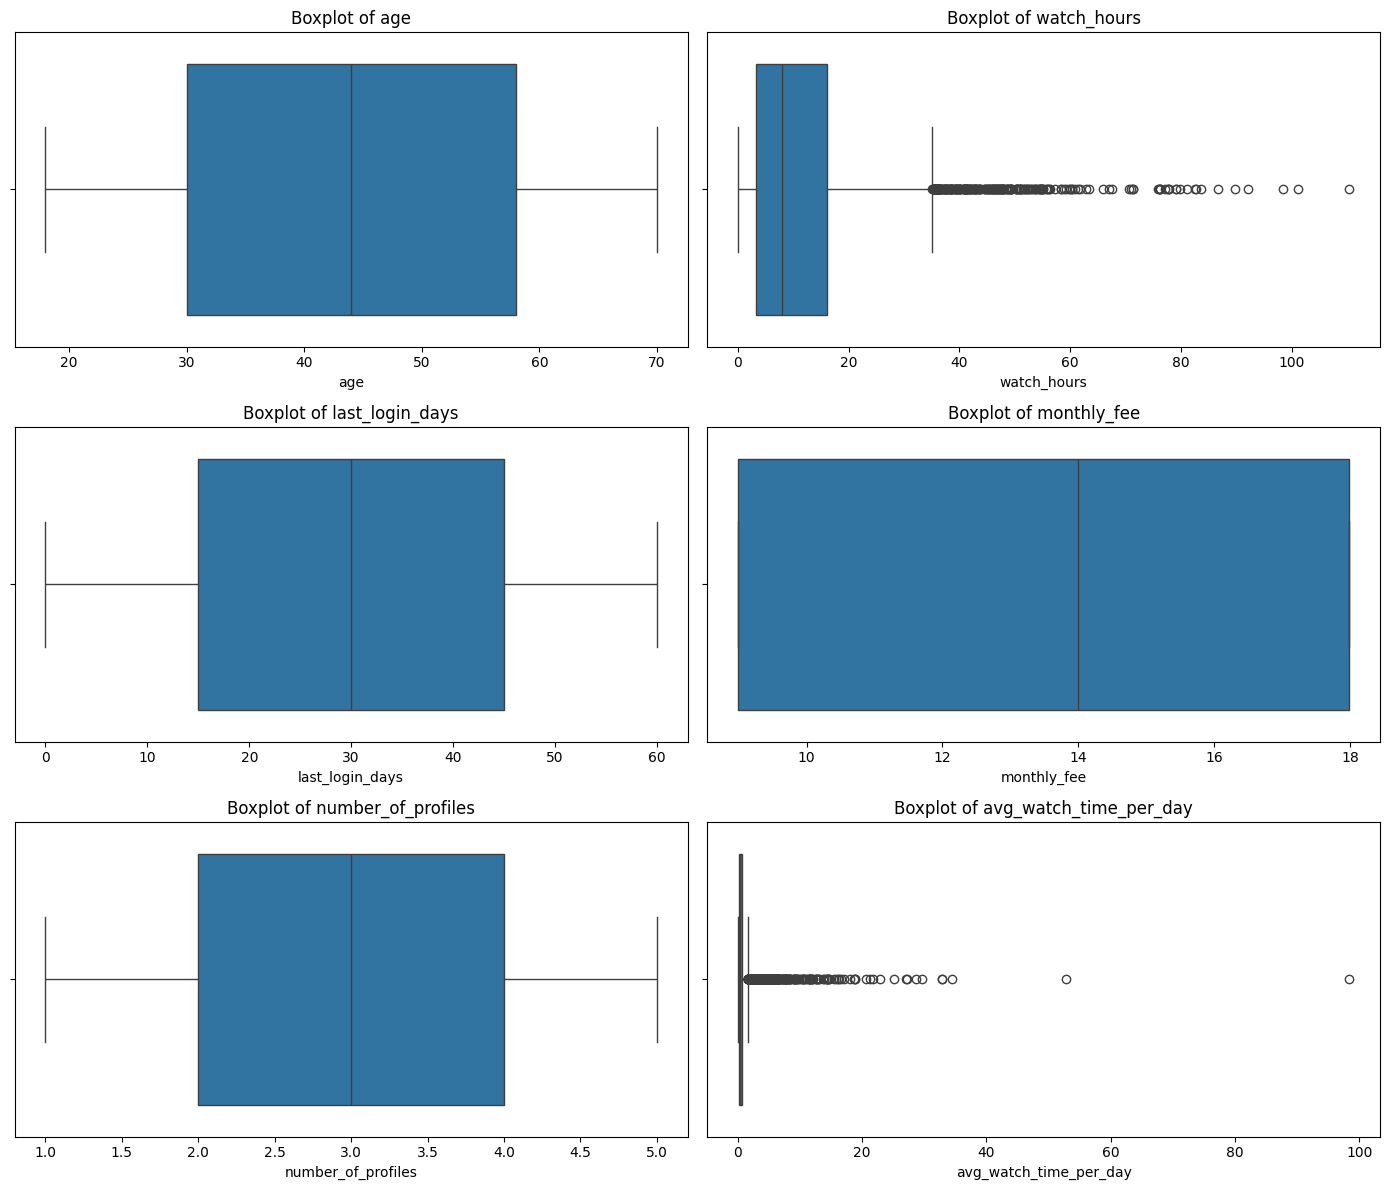

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(3, 2, figsize=(14, 12))

for ax, col in zip(axes.flat, numeric_cols):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(f"Boxplot of {col}")

plt.tight_layout()
plt.show()

In [19]:
categorical_cols = df.select_dtypes(
    include=["object", "category"]
).columns.drop("customer_id", errors="ignore")

print("Categorical Features:")
print(categorical_cols.tolist())

Categorical Features:
['gender', 'subscription_type', 'region', 'device', 'payment_method', 'favorite_genre']


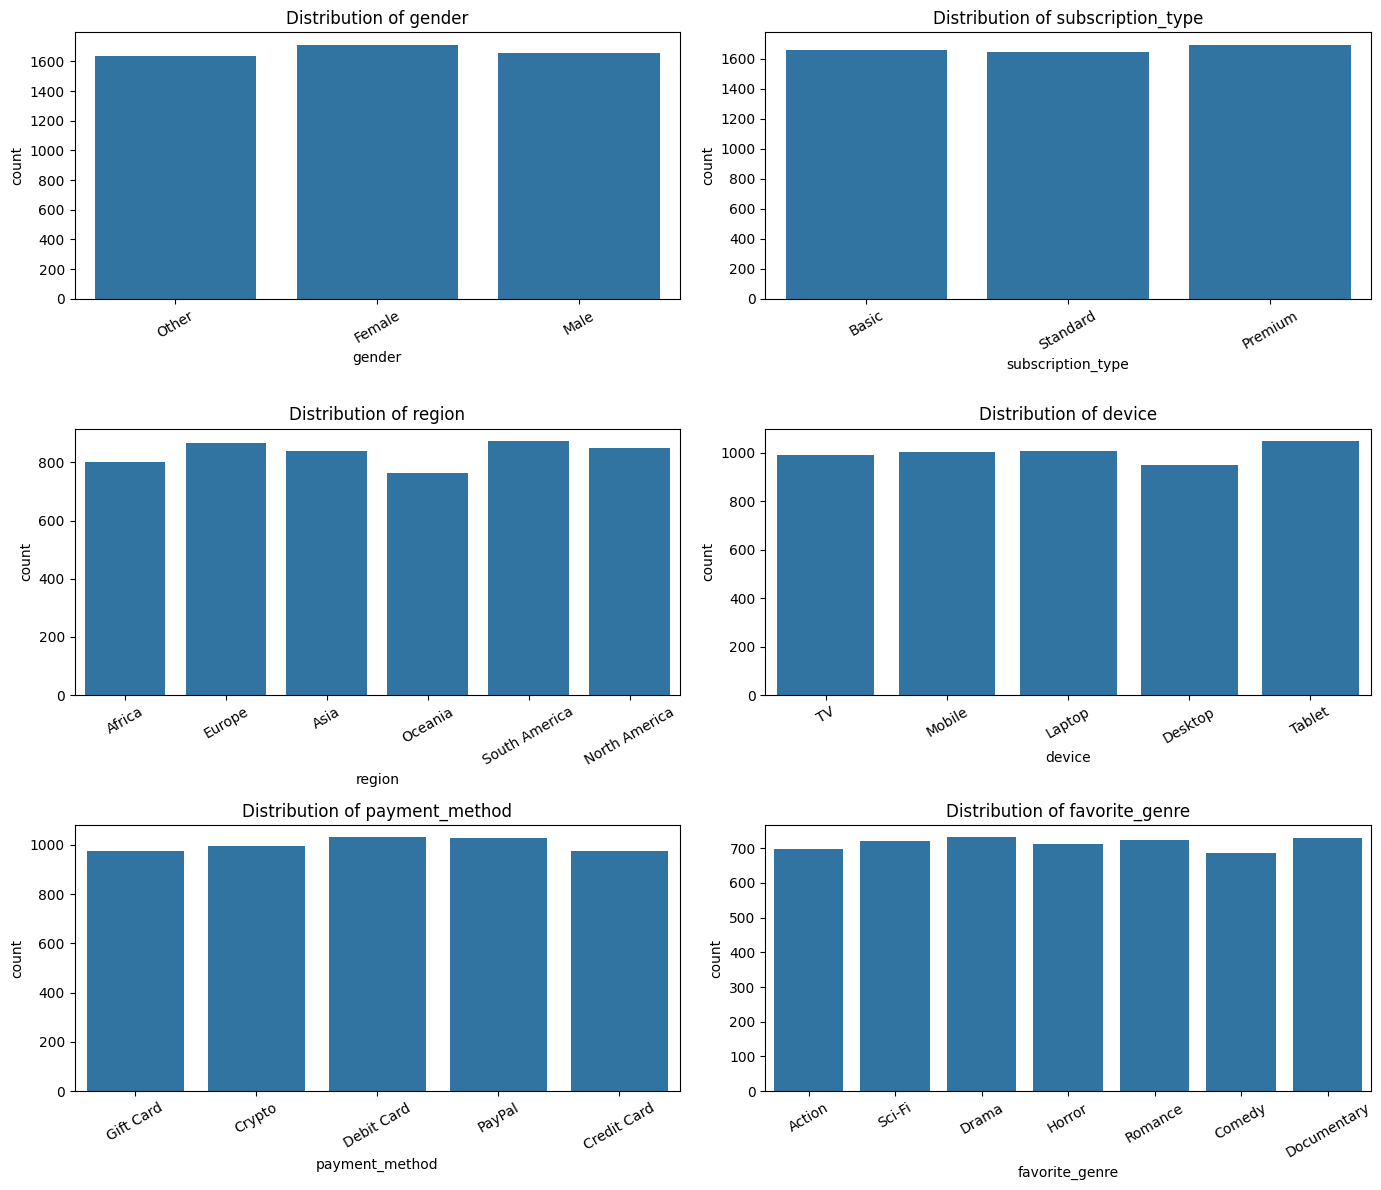

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

n_cols = 2
n_rows = int(np.ceil(len(categorical_cols) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 4 * n_rows))

for ax, col in zip(axes.flat, categorical_cols):
    sns.countplot(data=df, x=col, ax=ax)
    ax.set_title(f"Distribution of {col}")
    ax.tick_params(axis="x", rotation=30)

# Remove unused subplots
for ax in axes.flat[len(categorical_cols):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

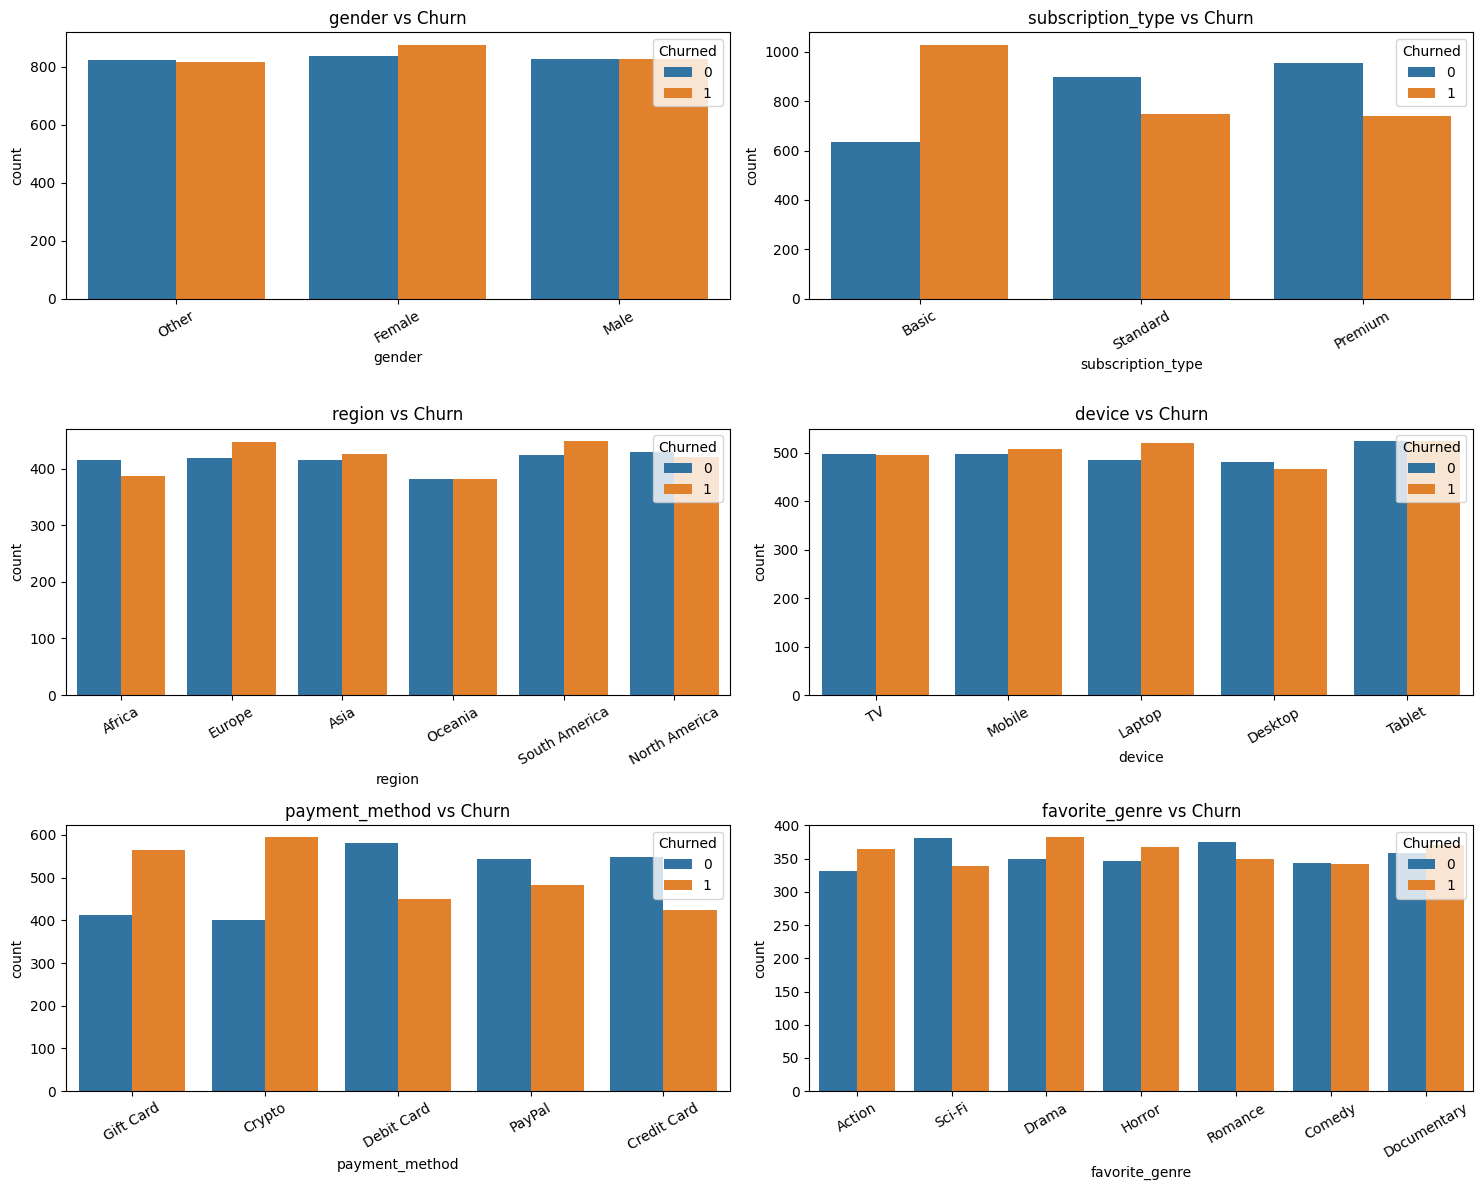

In [21]:
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))

for ax, col in zip(axes.flat, categorical_cols):
    sns.countplot(
        data=df,
        x=col,
        hue="churned",
        ax=ax
    )

    ax.set_title(f"{col} vs Churn")
    ax.tick_params(axis="x", rotation=30)
    ax.legend(title="Churned")

for ax in axes.flat[len(categorical_cols):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

In [22]:
for col in categorical_cols:
    print(f"\nChurn Rate by {col} (%):")

    churn_rate = (
        df.groupby(col)["churned"].mean() * 100
    )

    print(churn_rate.sort_values(ascending=False).round(2))


Churn Rate by gender (%):
gender
Female    51.08
Male      50.00
Other     49.79
Name: churned, dtype: float64

Churn Rate by subscription_type (%):
subscription_type
Basic       61.83
Standard    45.44
Premium     43.71
Name: churned, dtype: float64

Churn Rate by region (%):
region
Europe           51.67
South America    51.43
Asia             50.65
Oceania          50.07
North America    49.47
Africa           48.32
Name: churned, dtype: float64

Churn Rate by device (%):
device
Laptop     51.79
Mobile     50.50
Tablet     50.00
TV         49.95
Desktop    49.21
Name: churned, dtype: float64

Churn Rate by payment_method (%):
payment_method
Crypto         59.70
Gift Card      57.79
PayPal         47.08
Debit Card     43.69
Credit Card    43.58
Name: churned, dtype: float64

Churn Rate by favorite_genre (%):
favorite_genre
Action         52.37
Drama          52.26
Horror         51.47
Documentary    50.75
Comedy         49.93
Romance        48.28
Sci-Fi         47.08
Name: churned, 

In [23]:
print("Mean of Numerical Features by Churn Status:")

print(
    df.groupby("churned")[numeric_cols]
    .mean()
    .round(2)
    .T
)

Mean of Numerical Features by Churn Status:
churned                     0      1
age                     43.90  43.79
watch_hours             17.45   5.92
last_login_days         21.77  38.31
monthly_fee             14.25  13.13
number_of_profiles       3.25   2.80
avg_watch_time_per_day   1.59   0.16


In [24]:
print("Median of Numerical Features by Churn Status:")

print(
    df.groupby("churned")[numeric_cols]
    .median()
    .round(2)
    .T
)

Median of Numerical Features by Churn Status:
churned                     0      1
age                     44.00  44.00
watch_hours             13.86   4.06
last_login_days         19.00  41.00
monthly_fee             13.99  13.99
number_of_profiles       3.00   3.00
avg_watch_time_per_day   0.72   0.12


Correlation with Churn:
churned                   1.000000
last_login_days           0.471590
age                      -0.003515
monthly_fee              -0.152117
number_of_profiles       -0.158614
avg_watch_time_per_day   -0.272958
watch_hours              -0.479916
Name: churned, dtype: float64


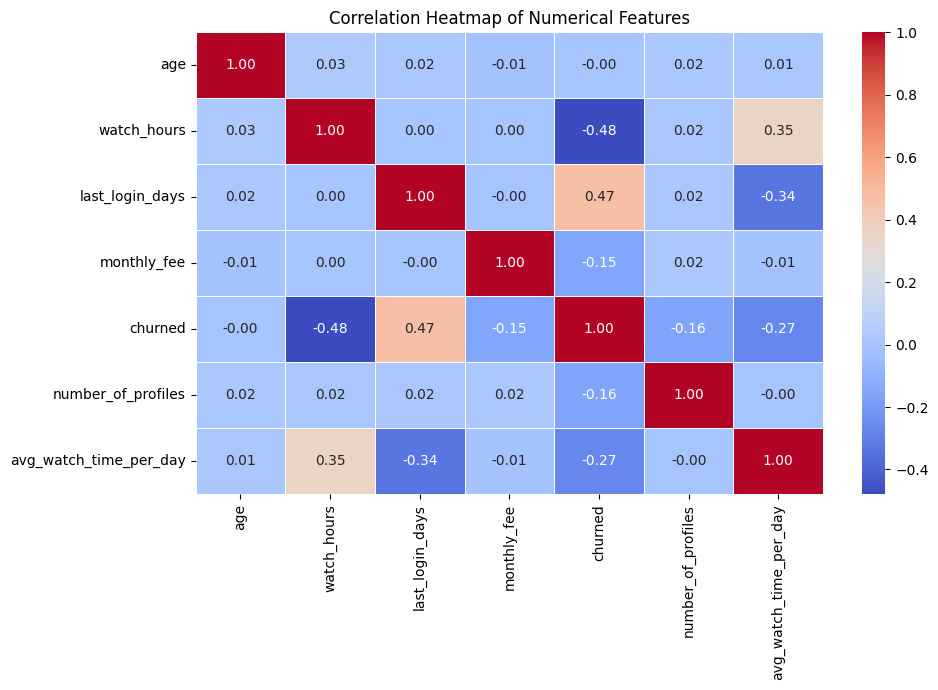

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select numerical columns, including churned
corr_matrix = df.select_dtypes(include="number").corr()

print("Correlation with Churn:")
print(corr_matrix["churned"].sort_values(ascending=False))

# Create heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

In [26]:
X = df.drop(columns=["customer_id", "churned"])
y = df["churned"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (5000, 12)
Target Shape: (5000,)


In [27]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting Target Distribution:")
print(y_test.value_counts(normalize=True))

Training Features: (4000, 12)
Testing Features: (1000, 12)

Training Target Distribution:
churned
1    0.503
0    0.497
Name: proportion, dtype: float64

Testing Target Distribution:
churned
1    0.503
0    0.497
Name: proportion, dtype: float64


In [28]:
import numpy as np
from sklearn.base import BaseEstimator, TransformerMixin

class InvalidWatchTimeHandler(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()

        X["avg_watch_time_per_day"] = (
            X["avg_watch_time_per_day"]
            .mask(X["avg_watch_time_per_day"] > 24, np.nan)
        )

        return X

In [29]:
invalid_handler = InvalidWatchTimeHandler()

X_train_checked = invalid_handler.fit_transform(X_train)

print("Missing values after validation:")
print(X_train_checked.isnull().sum())

print("\nOriginal training data missing values:")
print(X_train.isnull().sum())

Missing values after validation:
age                       0
gender                    0
subscription_type         0
watch_hours               0
last_login_days           0
region                    0
device                    0
monthly_fee               0
payment_method            0
number_of_profiles        0
avg_watch_time_per_day    9
favorite_genre            0
dtype: int64

Original training data missing values:
age                       0
gender                    0
subscription_type         0
watch_hours               0
last_login_days           0
region                    0
device                    0
monthly_fee               0
payment_method            0
number_of_profiles        0
avg_watch_time_per_day    0
favorite_genre            0
dtype: int64


In [30]:
import numpy as np

numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['age', 'watch_hours', 'last_login_days', 'monthly_fee', 'number_of_profiles', 'avg_watch_time_per_day']

Categorical Features:
['gender', 'subscription_type', 'region', 'device', 'payment_method', 'favorite_genre']


In [31]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Logistic Regression
numeric_lr = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Random Forest and XGBoost
numeric_tree = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

In [32]:
from sklearn.preprocessing import OneHotEncoder

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

In [33]:
from sklearn.compose import ColumnTransformer

# Logistic Regression preprocessing
preprocessor_lr = ColumnTransformer(
    transformers=[
        ("num", numeric_lr, numeric_features),
        ("cat", categorical_pipeline, categorical_features)
    ]
)

# Random Forest and XGBoost preprocessing
preprocessor_tree = ColumnTransformer(
    transformers=[
        ("num", numeric_tree, numeric_features),
        ("cat", categorical_pipeline, categorical_features)
    ]
)

In [34]:
preprocessing_lr = Pipeline(steps=[
    ("invalid_values", InvalidWatchTimeHandler()),
    ("preprocessor", preprocessor_lr)
])

preprocessing_tree = Pipeline(steps=[
    ("invalid_values", InvalidWatchTimeHandler()),
    ("preprocessor", preprocessor_tree)
])

In [35]:
X_train_lr_processed = preprocessing_lr.fit_transform(X_train)

X_train_tree_processed = preprocessing_tree.fit_transform(X_train)

print("Original Training Shape:", X_train.shape)

print("Logistic Regression Processed Shape:",
      X_train_lr_processed.shape)

print("Tree Models Processed Shape:",
      X_train_tree_processed.shape)

print("\nMissing Values After Preprocessing:")
print("Logistic Regression:",
      np.isnan(X_train_lr_processed).sum())

print("Tree Models:",
      np.isnan(X_train_tree_processed).sum())

Original Training Shape: (4000, 12)
Logistic Regression Processed Shape: (4000, 35)
Tree Models Processed Shape: (4000, 35)

Missing Values After Preprocessing:
Logistic Regression: 0
Tree Models: 0


In [36]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

lr_pipeline = Pipeline(steps=[
    ("preprocessing", preprocessing_lr),
    ("model", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

In [37]:
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)
from sklearn.model_selection import cross_validate

lr_scores = cross_validate(
    lr_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "precision": "precision",
        "recall": "recall",
        "f1": "f1",
        "roc_auc": "roc_auc"
    },
    n_jobs=-1
)

In [38]:
import numpy as np

print("Logistic Regression Cross-Validation Results\n")

for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    scores = lr_scores[f"test_{metric}"]

    print(f"{metric.upper()}:")
    print("Fold Scores:", np.round(scores, 4))
    print("Mean:", round(scores.mean(), 4))
    print("Std:", round(scores.std(), 4))
    print()

Logistic Regression Cross-Validation Results

ACCURACY:
Fold Scores: [0.8962 0.9    0.8888 0.8888 0.9   ]
Mean: 0.8948
Std: 0.0051

PRECISION:
Fold Scores: [0.8958 0.8985 0.8826 0.8886 0.891 ]
Mean: 0.8913
Std: 0.0056

RECALL:
Fold Scores: [0.898  0.903  0.898  0.8908 0.9132]
Mean: 0.9006
Std: 0.0074

F1:
Fold Scores: [0.8969 0.9007 0.8903 0.8897 0.902 ]
Mean: 0.8959
Std: 0.0051

ROC_AUC:
Fold Scores: [0.9641 0.9702 0.9634 0.9673 0.9689]
Mean: 0.9668
Std: 0.0026



In [39]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

rf_pipeline = Pipeline(steps=[
    ("preprocessing", preprocessing_tree),
    ("model", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

In [40]:
rf_scores = cross_validate(
    rf_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "precision": "precision",
        "recall": "recall",
        "f1": "f1",
        "roc_auc": "roc_auc"
    },
    n_jobs=1
)

In [41]:
print("Random Forest Cross-Validation Results\n")

for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    scores = rf_scores[f"test_{metric}"]

    print(f"{metric.upper()}:")
    print("Fold Scores:", np.round(scores, 4))
    print("Mean:", round(scores.mean(), 4))
    print("Std:", round(scores.std(), 4))
    print()

Random Forest Cross-Validation Results

ACCURACY:
Fold Scores: [0.9788 0.9625 0.97   0.9788 0.985 ]
Mean: 0.975
Std: 0.0079

PRECISION:
Fold Scores: [0.98   0.9697 0.9871 0.9801 0.9851]
Mean: 0.9804
Std: 0.006

RECALL:
Fold Scores: [0.9776 0.9552 0.9527 0.9777 0.9851]
Mean: 0.9697
Std: 0.0131

F1:
Fold Scores: [0.9788 0.9624 0.9696 0.9789 0.9851]
Mean: 0.975
Std: 0.008

ROC_AUC:
Fold Scores: [0.9976 0.9941 0.9949 0.9984 0.9991]
Mean: 0.9968
Std: 0.002



In [42]:
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline

xgb_pipeline = Pipeline(steps=[
    ("preprocessing", preprocessing_tree),
    ("model", XGBClassifier(
        n_estimators=100,
        max_depth=4,
        learning_rate=0.1,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

In [43]:
xgb_scores = cross_validate(
    xgb_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "precision": "precision",
        "recall": "recall",
        "f1": "f1",
        "roc_auc": "roc_auc"
    },
    n_jobs=1
)

In [44]:
print("XGBoost Cross-Validation Results\n")

for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    scores = xgb_scores[f"test_{metric}"]

    print(f"{metric.upper()}:")
    print("Fold Scores:", np.round(scores, 4))
    print("Mean:", round(scores.mean(), 4))
    print("Std:", round(scores.std(), 4))
    print()

XGBoost Cross-Validation Results

ACCURACY:
Fold Scores: [0.9938 0.99   0.99   0.9938 0.9962]
Mean: 0.9928
Std: 0.0024

PRECISION:
Fold Scores: [0.9926 0.9975 0.995  0.9975 0.995 ]
Mean: 0.9955
Std: 0.0018

RECALL:
Fold Scores: [0.995  0.9826 0.9851 0.9901 0.9975]
Mean: 0.9901
Std: 0.0057

F1:
Fold Scores: [0.9938 0.99   0.99   0.9938 0.9963]
Mean: 0.9928
Std: 0.0024

ROC_AUC:
Fold Scores: [0.9997 0.9981 0.9985 0.9997 0.9997]
Mean: 0.9992
Std: 0.0007



In [45]:
best_pipeline = xgb_pipeline

best_pipeline.fit(X_train, y_train)

print("Final XGBoost model trained successfully!")

Final XGBoost model trained successfully!


In [46]:
y_pred = best_pipeline.predict(X_test)

y_prob = best_pipeline.predict_proba(X_test)[:, 1]

print("First 10 predicted classes:", y_pred[:10])
print("First 10 churn probabilities:", y_prob[:10])

First 10 predicted classes: [0 1 0 1 1 1 1 1 0 0]
First 10 churn probabilities: [9.3838818e-05 9.6554649e-01 1.8692309e-02 9.9869126e-01 9.9921989e-01
 9.9813640e-01 9.8420376e-01 9.9993908e-01 4.9043737e-02 8.2659841e-02]


In [47]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

print("XGBoost Test Results\n")

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall:", round(recall_score(y_test, y_pred), 4))
print("F1-score:", round(f1_score(y_test, y_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

XGBoost Test Results

Accuracy: 0.993
Precision: 0.998
Recall: 0.9881
F1-score: 0.993
ROC-AUC: 0.9997

Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99       497
           1       1.00      0.99      0.99       503

    accuracy                           0.99      1000
   macro avg       0.99      0.99      0.99      1000
weighted avg       0.99      0.99      0.99      1000



Confusion Matrix:
[[496   1]
 [  6 497]]


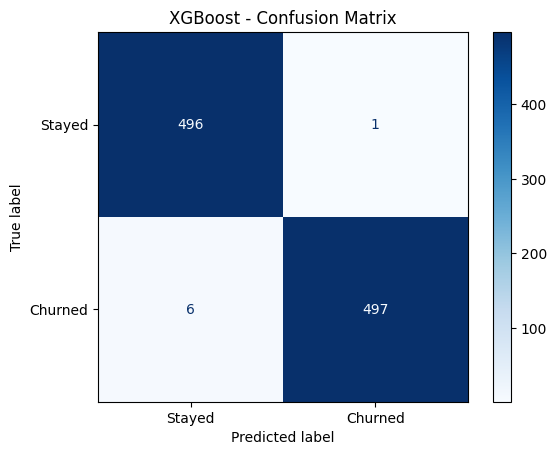

In [48]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Stayed", "Churned"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("XGBoost - Confusion Matrix")
plt.show()

In [50]:
import joblib

joblib.dump(best_pipeline, "churn_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [51]:
%%writefile custom_transformers.py

import numpy as np
from sklearn.base import BaseEstimator, TransformerMixin

class InvalidWatchTimeHandler(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()

        X["avg_watch_time_per_day"] = (
            X["avg_watch_time_per_day"]
            .mask(X["avg_watch_time_per_day"] > 24, np.nan)
        )

        return X

Writing custom_transformers.py


In [52]:
import joblib
from custom_transformers import InvalidWatchTimeHandler

# Reuse our already-trained model
deploy_pipeline = best_pipeline

# Replace the custom transformer
deploy_pipeline.named_steps["preprocessing"].set_params(
    invalid_values=InvalidWatchTimeHandler()
)

# Save the updated pipeline
joblib.dump(deploy_pipeline, "churn_model.pkl")

print("Deployment-ready model saved successfully!")

Deployment-ready model saved successfully!


In [53]:
loaded_model = joblib.load("churn_model.pkl")

print("Model loaded successfully!")

prediction = loaded_model.predict(X_test.head(1))

probability = loaded_model.predict_proba(X_test.head(1))[:, 1]

print("Predicted Class:", prediction[0])
print("Churn Probability:", round(probability[0] * 100, 2), "%")

Model loaded successfully!
Predicted Class: 0
Churn Probability: 0.01 %


In [54]:
from google.colab import files

files.download("churn_model.pkl")
files.download("custom_transformers.py")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [55]:
from google.colab import files

files.download("churn_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [56]:
import sklearn
import xgboost
import numpy
import pandas
import joblib
import sys

print("Python:", sys.version)
print("Scikit-learn:", sklearn.__version__)
print("XGBoost:", xgboost.__version__)
print("NumPy:", numpy.__version__)
print("Pandas:", pandas.__version__)
print("Joblib:", joblib.__version__)

Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Scikit-learn: 1.6.1
XGBoost: 3.4.1
NumPy: 2.4.6
Pandas: 2.2.3
Joblib: 1.6.0
